<a href="https://colab.research.google.com/github/orianathevissen-web/Group-project---NHANES/blob/main/NHANES_group_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Part 1 : Explore, preprocess and quality-control the data**

In [ ]:
import numpy as np                       # gives numerical tools
import pandas as pd                      # provides DataFrames (tables). One row is one person, one column is one variable
import matplotlib.pyplot as plt          # graphs
import seaborn as sns                    # statistical graphs, it makes statistical plots shorter

sns.set_style("whitegrid")               # Adds a grid to plots and make pandas show more columns when printing. No effect on the analysis
sns.set_palette("deep")

In [ ]:
from google.colab import files
uploaded = files.upload()   # upload both CSV's

Saving NHANES_20212023_codebook_filtered 1.csv to NHANES_20212023_codebook_filtered 1 (1).csv
Saving NHANES_20212023_merged_filtered 1.csv to NHANES_20212023_merged_filtered 1 (1).csv


In [ ]:
!ls                         # This runs a shell command (the !) thatlists files, so you can see the exact file names

'NHANES_20212023_codebook_filtered 1 (1).csv'
'NHANES_20212023_codebook_filtered 1.csv'
'NHANES_20212023_merged_filtered 1 (1).csv'
'NHANES_20212023_merged_filtered 1.csv'
 sample_data


In [ ]:
DATA_FILE = "NHANES_20212023_merged_filtered 1.csv"
CODEBOOK_FILE = "NHANES_20212023_codebook_filtered 1.csv"

data = pd.read_csv(DATA_FILE)                          # reads a CSV into a DataFrame; The data file = UTF-8, which is the default
codebook = pd.read_csv(CODEBOOK_FILE, encoding="cp1252")

# encoding = rule that maps bytes into characters
# codeboek is cp1252 and reading it as UTF-8 crashes on special characters

print(data.shape)
codebook.head()

#.shape = returns (rows,columns)
# rows = samples (participants)
# columns = features (variables)

(11933, 486)


,variable,label,file,component
0,SEQN,Respondent sequence number,DEMO_L,Demographics
1,SDDSRVYR,Data release cycle,DEMO_L,Demographics
2,RIDSTATR,Interview/Examination status,DEMO_L,Demographics
3,RIAGENDR,Gender,DEMO_L,Demographics
4,RIDAGEYR,Age in years at screening,DEMO_L,Demographics


Question 1: samples, features and variables

In [ ]:
print("Samples x features:", data.shape)
print("SEQN uniek:", data["SEQN"].is_unique)
# SEQN is the participant ID; this is not a feature, only an identifier
# is_unique checks that no person appears twice. If it were False we'd have duplicate samples

print(data.dtypes.value_counts())
print(codebook["component"].value_counts())
# dtypes is the storage type per column (int, float, string)
# value_counts() counts how many columns of each
# component shows which part of NHANES a variable comes from (demographics, laboratory, questionnaire, examination)

Samples x features: (11933, 486)
SEQN uniek: True
float64    475
int64       10
object       1
Name: count, dtype: int64
component
Laboratory       387
Questionnaire     40
Examination       32
Demographics      27
Name: count, dtype: int64


In [ ]:
def guess_type(s):
    n = s.nunique(dropna=True)
    if s.dtype == "object":
        return "nominal (string)"
    if n <= 2:
        return "nominal (binair)"
    if n <= 10:
        return "categorical (nominal/ordinal)"
    if pd.api.types.is_integer_dtype(s):
        return "discrete"
    return "continu"

# it takes one column "s" and counts its unique values "n"
# dropna=True : ignores missing
# Text columns are categories. Two values means binary. Up to 10 values is probably a coded category.
# Many whole numbers is discrete. Many decimal values is continues.

types = data.apply(guess_type).rename("type_guess")
print(types.value_counts())

# data.apply(f) runs f on every column. The result is a series with one type guess per columns, named type_guess

type_guess
continu                          277
nominal (binair)                 149
categorical (nominal/ordinal)     56
discrete                           3
nominal (string)                   1
Name: count, dtype: int64


The four variable types:
- Nominal: categories with no order. Example: sex, ethnicity
- Ordinal: categories with a meaningful order but unequal distances. Example: education level
- Discrete: countable whole numbers. Examples: age in years, minutes sitting.
- Continuous: any value in a range. Examples: weight, HbA1c, cholesterol

In [ ]:
overview = (codebook.set_index("variable")[["label", "component"]]
             .join(types, how="right"))
overview.sample(20, random_state=1)

#set_index("variable") = makes the variable name the row label, so it can be matched with types (also indexed by variable name)
#join (..., how="right") = keeps every columns of data, even if the codebook lacks it
#.sample(20, random_state=1) = shows 20 random rows. A fixed random_state gives the same 20 every time (reproducibility)

,label,component,type_guess
LBDPTALC,Docosatetraenoic acid (C22:4n-6) cmt cd,Laboratory,nominal (binair)
LBDPDALC,Docosanoic acid (C22:0) comment code,Laboratory,nominal (binair)
LBXPNR,15-Tetracosenoic acid (C24:1n9) (%),Laboratory,continu
LBDVDBLC,"Blood 1,4-Dichlorobenzene Comment Code",Laboratory,nominal (binair)
LBXHBC,Hepatitis B core antibody,Laboratory,categorical (nominal/ordinal)
LBDBMNLC,Blood manganese comment code,Laboratory,nominal (binair)
LBDHRPLC,HS C-Reactive Protein Comment Code,Laboratory,nominal (binair)
LBDPPMLC,Palmitic acid (C16:0) comment code,Laboratory,nominal (binair)
BPXODI3,Diastolic - 3rd oscillometric reading,Examination,continu
LBXSASSI,Aspartate Aminotransferase (AST) (IU/L),Laboratory,continu


In [ ]:
codebook[codebook["label"].str.contains("blood pressure|systolic", case=False, na=False)]
# This filters the codebook rows whose label contains those words
# | means or
# case=False ignores capitals, and na=FALSE treats missing labels as "no match". Without it, the filter would contain NaN and crash

,variable,label,file,component
29,BPXOSY1,Systolic - 1st oscillometric reading,BPXO_L,Examination
31,BPXOSY2,Systolic - 2nd oscillometric reading,BPXO_L,Examination
33,BPXOSY3,Systolic - 3rd oscillometric reading,BPXO_L,Examination


Question 2: missing values

In [ ]:
miss = data.isnull().mean().sort_values(ascending=False) * 100
print(miss.describe())
print((miss > 50).sum(), "columns with >50% missing")
miss.head(20)

#isnull() gives a True/False table (True = missing)
#.mean() per column averages True=1 and False=0, which gives the fraction missing
# *100 makes it a percentage, and sort_values(ascending=False) puts the worst percentage first
#describ() gives min, median and max of these percentages
#(miss > 50) is a True/False series, and .sum() counts the Trues, ie how many columns exceed 50%

count    486.000000
mean      53.492045
std       23.013518
min        0.000000
25%       38.422861
50%       41.221822
75%       75.341490
max      100.000000
dtype: float64
191 columns with >50% missing


,0
BMIHEAD,100.000000
DBQ073D,99.865918
LBXHCG,99.849158
BMIRECUM,99.849158
DBQ073E,99.824017
PHAALCMN,99.790497
PHAALCHR,99.790497
PHACOFMN,99.756976
PHACOFHR,99.756976
DBQ073C,99.446912


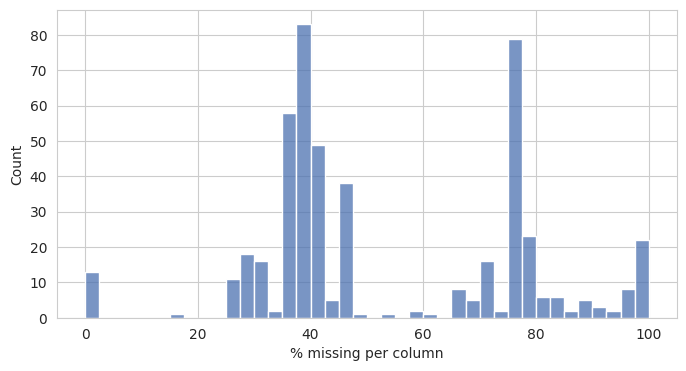

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(miss, bins=40)
plt.xlabel("% missing per column")
plt.show()

#sns.histplot will give us a histogram of % missing per column. You'll see many columns with almost nothing missing and a large group with a lot missing. That group is the signal that something systematic is going on

Why are values missing? (theoretical background)
- MCAR (missing completely at random): missingness unrelated to anything, eg a lab sample is dropped. Harmless, apart from losing samples
- MAR (missing at random): dapends on other observed variables, eg older people skip a test
- MNAR (missing not at random): depends on the missing value itself, eg high earners refuse to report income. This is the dangerous one, because it biases results
- Structural missingness (by design): the question or test was never meant for this person. NHANES is full of it, and it is the main reason here.

Why do they miss?

In [ ]:
data["agegroup"] = pd.cut(data["RIDAGEYR"], [-1, 11, 17, 39, 59, 120],
                                labels=["<12", "12-17", "18-39", "40-59", "60+"])

columns = ["BPXOSY1", "BMXWAIST", "LBXTC", "LBXGH", "LBXIN", "ALQ130", "DBQ010"]
print(data.groupby("agegroup", observed=True)[columns]
          .apply(lambda g: g.isnull().mean() * 100).round(1))

#pd.cut sorts a number into bins. Bins are (-1,11],(11,17],.. so ages 0-11, 12-17, 18-39, 40-59 and 60+. The reason why -1 is used, is so that we include age 0.
#grouby splits the table into age groups
#[columns] selects some variables
#apply(lambda g:...) computes, within each group, the % missing for each variable
#observed=True only shows groups that actually occur, and avoids a warning

          BPXOSY1  BMXWAIST  LBXTC  LBXGH  LBXIN  ALQ130  DBQ010
agegroup                                                        
<12          77.6      47.2   80.4  100.0  100.0   100.0    43.4
12-17        33.3      33.1   45.4   42.3   73.1   100.0   100.0
18-39        27.9      27.8   34.0   30.6   64.7    47.6   100.0
40-59        24.3      25.3   28.1   24.8   59.9    47.6   100.0
60+          23.2      25.6   28.2   24.5   59.2    53.4   100.0


What is learned: if a variable is 100% missing in children and 0% in adults, the question was only asked to adults. That is a skip pattern, not an error. It also justifies restricting to adults later.

In [ ]:
# Sober subsample: who isn't in this group, is missing insuline/glucose
print(data.groupby(data["WTSAF2YR"].isnull())[["LBXIN", "LBXGLU"]]
          .apply(lambda g: g.isnull().mean() * 100).round(1))

          LBXIN  LBXGLU
WTSAF2YR               
False      12.2     8.1
True      100.0   100.0


WTSAF2YR is the sampling weight of the fasting subsample. It is only filled in for people who were randomly assigned to the fasting morning session. Grouping by “is this weight missing?” shows that insulin and glucose are missing for exactly those not in that subsample. This is again missing by design.

Surveys store "refused" or "don't know" as numbers such as 7, 9, 77, 99, 777, 7777, 9999. They look like real answers. If 9999 in "minutes sitting" was left, the model would think someone sitting that long

In [ ]:
print(codebook["component"].unique())   # look how the questionnairy-component is called

['Demographics' 'Examination' 'Laboratory' 'Questionnaire']


In [ ]:
questions_comp = codebook.loc[codebook["component"].str.contains("question", case=False, na=False), "variable"]
questionlist = [v for v in questions_comp if v in data.columns]
if len(questionlist) == 0:               # fallback if the component has a different name
    questionlist = list(data.select_dtypes("number").columns)

#This selects the variable names whose component is a questionnaire (codes occur mainly in questionnaires). The list comprehension keeps only names that actually exist in the data.
codes = {7, 9, 77, 99, 777, 999, 7777, 9999}
report = []
for v in questionlist:
    s = data[v].dropna()
    if len(s) > 0 and s.max() in codes:
        second = s[s < s.max()].max()
        report.append((v, s.max(), second))

  #For each question variable we take its maximum. If the max is a typical code, we also look at the largest value below it.
  #A jump from 1300 -> 9999, means 9999 is a code
  #A jump from 8 -> 9 is ambiguous, so the label has to be checked
  #This is a screening tool that produces candidates to verify manually, not an automatic cleaner

report_df = pd.DataFrame(report, columns=["variable", "max (code?)", "largest value"])
report_df.merge(codebook[["variable", "label"]], left_on="variable", right_on="variable", how="left")

#A merge is a database join. It attaches the human-readable label to each candidate so you can judge it

,variable,max (code?),largest value,label
0,ALQ111,9.0,2.0,Ever had a drink of any kind of alcohol
1,ALQ121,99.0,77.0,Past 12 mos how often drink alc bev
2,ALQ130,999.0,777.0,Avg # alcoholic drinks/day/past 12 mos
3,ALQ142,99.0,77.0,# days have 4/5 drinks/past 12 mos
4,ALQ270,99.0,77.0,# times 4/5 drinks in 2hrs/past 12 mos
5,ALQ280,99.0,77.0,# times 8+ drinks in 1 day/past 12 mos
6,ALQ151,9.0,7.0,Ever have 4/5 or more drinks every day
7,ALQ170,999.0,777.0,# times 4/5 drinks on occasion/past mo
8,DBQ010,9.0,2.0,Ever breastfed or fed breastmilk
9,DBQ073A,99.0,10.0,Type of milk first fed - whole milk


How to handle missingness?
1) restrict to relevant population (adults, non-pregnant, with a target), which removes much structural missingness
2) drop columns with too much missing
3) drop rows without a target
4) impute only inside a pipeline fitted on training data, never on full data
5) mention that the leftover missingness is partly not random, so bias is possible

**Code under this text is a TO DO**

In [ ]:
# Transform codes to NaN for columns that we checked(check the codebook!)
code_cols = ["DMDEDUC2", "ALQ130", "DBD030"]   # <- change after checking the table above
code_cols = [c for c in code_cols if c in data.columns]
for c in code_cols:
    data[c] = data[c].replace([7, 9, 77, 99, 777, 999, 7777, 9999], np.nan)

Question 3: abnormal samples en features

In [ ]:
adults = data[(data["RIDAGEYR"] >= 18) & (data["RIDEXPRG"] != 1)].copy()  # adults, non-pregnant
print(len(adults))

#RIDEXPRG is pregnancy status (1 = pregnant)
#!=1 is also True for Nan, so men and unknown cases stay in
#.copy() makes an independent table, so later edits don't trigger pandas

8112


Why adults?
Blood pressure norms differ in children, and most questions are asked to only adults

Why exclude pregnant woman?
Weight and blood pressure change in pregnancy, so they are a biologically different group

In [ ]:
core = ["RIDAGEYR", "BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "LBXTC", "LBXGH", "LBXHSCRP", "LBXIN", "BPXOSY1"]
core = [c for c in core if c in adults.columns]
adults[core].describe().T

#describe() gives count, mean, std, min, quartiles and max per variable
#.T transposes so variables become rows
#look for impossible values (negative weight), codes (9999) and top-coding. NHANES top-codes age at 80 and INDFMPIR at 5


,count,mean,std,min,25%,50%,75%,max
RIDAGEYR,8112.0,52.256287,18.528762,18.00,36.0,55.00,68.00,80.00
BMXWT,6207.0,82.902412,22.466494,27.90,67.1,79.50,95.00,248.20
BMXHT,6221.0,166.982141,10.064061,133.00,159.7,166.60,174.30,200.70
BMXBMI,6194.0,29.657410,7.390189,11.10,24.5,28.30,33.40,74.80
BMXWAIST,5983.0,100.456159,17.173581,59.60,88.1,99.00,111.00,187.00
LBXTC,5681.0,186.814821,42.475107,62.00,157.0,184.00,213.00,438.00
LBXGH,5965.0,5.768634,1.100018,3.20,5.2,5.50,5.90,17.10
LBXHSCRP,5785.0,3.817850,7.325118,0.11,0.8,1.79,4.13,150.92
LBXIN,3153.0,14.352715,24.161036,0.35,5.9,9.34,15.63,551.10
BPXOSY1,6084.0,122.656476,18.458960,73.00,110.0,120.00,133.00,232.00


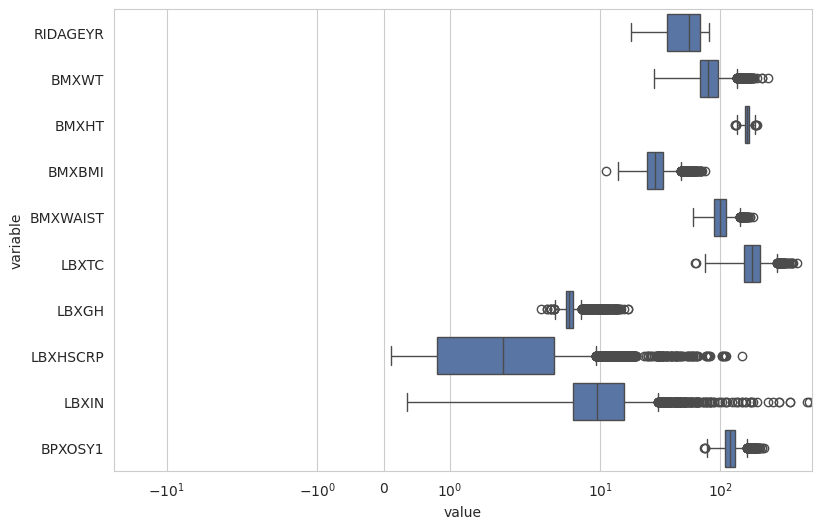

In [ ]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=adults[core].melt(), x="value", y="variable")
plt.xscale("symlog")
plt.show()

#melt() converts a wide table (one column per variable) to long format (columns variable and value), which is what seaborn needs for one box per variable
#symlog is a symmetric log scale. The variables have very different ranges (age 50, hsCRP 2, cholesterol 180), so a linear axis would squesh the small ones
#symlog is logarithmic for large values and linear near zero, so it also handles zeros

In [ ]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

adults[core].apply(iqr_outliers).sort_values(ascending=False)

#Turkey's rule: a value more than 1,5xIQR below Q1 or above Q3 is flagged as an outlier (the whiskers of a boxplot)

,0
LBXGH,495
LBXHSCRP,489
LBXIN,228
BMXBMI,182
BMXWT,157
BPXOSY1,138
BMXWAIST,77
LBXTC,70
BMXHT,9
RIDAGEYR,0


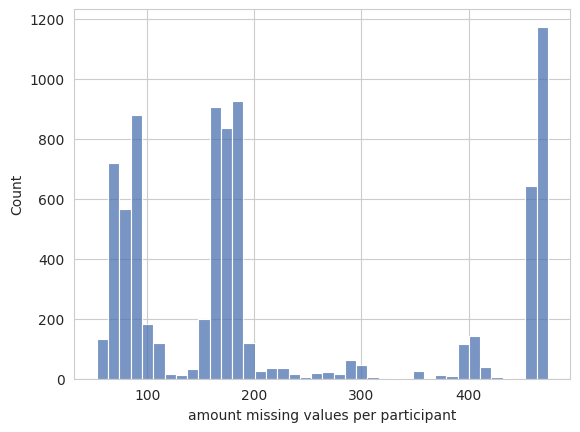

In [ ]:
adults["n_missing"] = adults.isnull().sum(axis=1)
sns.histplot(adults["n_missing"], bins=40)
plt.xlabel("amount missing values per participant")
plt.show()

#axis=1 sums across the row, giving the number of missing values per person
#if the histogram below has two humps, there are two kinds of participants (those who completed, the examination and those who only did the interview). that would be a sample-level technical differnece

Technical error vs interesting biology:
- Technical: impossible values, codes like 9999, top-coding (age 80 means 80 or older), people who skipped examinations
- Biology: hsCRP > 10 (acute inflammation), HbA1c > 6,5 (diabetes), BMI>40, systolic BP>180. These are rare but real, and they are exactly the variation we want to model. We keep them. Removing them would make the omdel blind to precisely the high-risk people

Quetion 4: preprocessing

In [ ]:
#Making the target
sbp_cols = ["BPXOSY1", "BPXOSY2", "BPXOSY3"]
adults["systolic_bp"] = adults[sbp_cols].mean(axis=1)
adults = adults.dropna(subset=["systolic_bp"])
print("Adults with target:", len(adults))

#Blood pressure was measured up to three times. The mean per row (axis=1) averages the available readings and skips NaN. Averaging reduces random measurement noise. The tutorial does the same.
#dropna(subset=[...]) removes people with no reading at all. Without a target we can’t train or evaluate.

Adults with target: 6084


What does data leakage mean?

Leakage means the features contain information that wouldn’t be available at prediction time, or that is nearly a copy of the target. The model then looks excellent but is useless in practice. The tutorial demonstrates this: R² went from 0.29 to 0.49 with leaky columns. Here, the diastolic readings come from the same cuff in the same minute, so they leak. Hypertension diagnosis or medication would also leak.

In [ ]:
#Deleting non-features

# Leakage: diastolic + de systolic measurements
leaky = ["BPXODI1", "BPXODI2", "BPXODI3", "BPXOSY1", "BPXOSY2", "BPXOSY3"]
pols = ["BPXOPLS1", "BPXOPLS2", "BPXOPLS3"]
adults["pols_mean"] = adults[pols].mean(axis=1)

design = [c for c in adults.columns if c.startswith("WT")] + \
         ["SEQN", "SDDSRVYR", "RIDSTATR", "SDMVSTRA", "SDMVPSU",
          "BPAOARM", "BPAOCSZ", "n_missing", "agegroup"] + pols
lc_flags = [c for c in adults.columns if c.endswith("LC")]

drop_cols = [c for c in leaky + design + lc_flags + ["systolic_bp"] if c in adults.columns]
features = adults.drop(columns=drop_cols)
print(features.shape)

#Columns described below aren't biological features:
#WT... are sampling weights (how many people each participant represents; NHANES oversamples groups)
#SDMVSTRA and SDMVPSU are survey design variables used for variance estimation.
#BPAOARM (which arm) and BPAOCSZ (cuff size) describe the measurement procedure. Kept for the PCA, to test for technical effects.
#...LC columns are flags (“below the detection limit”), derived from the lab value itself.
#drop removes those columns. The list comprehension [c for c in ... if c in adults.columns] avoids errors for names that don’t exist.

(6084, 337)


In [ ]:
#double columns

corr = features.select_dtypes("number").corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
             .stack().sort_values(ascending=False))
pairs[pairs > 0.95].head(30)

#.corr() is the Pearson correlation matrix. .abs() takes absolute values, since −0.99 is as redundant as +0.99.
#The matrix is symmetric and has 1s on the diagonal. np.triu(..., 1) keeps only the upper triangle without the diagonal, so each pair appears once and nothing is correlated with itself.
#.where(mask) keeps those cells and turns the rest into NaN. .stack() flattens to a list of (variable A, variable B) pairs and drops the NaN. sort_values puts the strongest first.

PHAALCMN  LBDTFRSI    1.0
PHAALCHR  LBDTFRSI    1.0
LBXBGE    LBDBGESI    1.0
URXUCR    URXCRS      1.0
LBXSGB    LBDSGBSI    1.0
LBXSAL    LBDSALSI    1.0
LBXAGP    PHAALCMN    1.0
PHAALCMN  LBXFER      1.0
          LBDFERSI    1.0
LBXAGP    PHAALCHR    1.0
LBXV2A    DBQ370      1.0
LBXHCG    LBXTFR      1.0
PHACOFHR  PHAALCMN    1.0
PHAALCHR  LBDFERSI    1.0
DMDYRUSR  PHACOFMN    1.0
PHAALCHR  LBXFER      1.0
PHACOFHR  PHASUPMN    1.0
LBXAGP    LBXHCG      1.0
PHACOFMN  PHAALCMN    1.0
PHACOFHR  PHASUPHR    1.0
DMDHSEDZ  LBDHEM      1.0
LBDFERSI  LBXHCG      1.0
LBXFER    LBDFERSI    1.0
PHACOFMN  PHASUPMN    1.0
          PHASUPHR    1.0
PHAALCHR  LBXTFR      1.0
DMDHRGND  LBDHEM      1.0
PHAALCMN  LBXTFR      1.0
PHAGUMHR  DBD381      1.0
DMDYRUSR  PHACOFHR    1.0
dtype: float64

In [ ]:
todelete = {b for a, b in pairs[pairs > 0.99].index}
print(len(todelete), "columns deleted:", sorted(todelete)[:15])
features = features.drop(columns=todelete)

#For each pair with correlation above 0.99, we remove the second variable. That is almost always the same measurement in a different unit (LBXTC mg/dL vs LBDTCSI mmol/L). Why: redundant features add no information, cause multicollinearity (unstable coefficients in linear models), and increase dimensionality. This step does not use the target, so it causes no leakage.

62 columns deleted: ['DBD381', 'DBQ370', 'DBQ424', 'LBD17HSI', 'LBDAMHSI', 'LBDANDSI', 'LBDBCDSI', 'LBDBGESI', 'LBDBGMSI', 'LBDBMNSI', 'LBDBPBSI', 'LBDBSESI', 'LBDDHESI', 'LBDES1SI', 'LBDESOSI']


In [ ]:
features = features.loc[:, features.isnull().mean() < 0.4]
features = features.loc[:, features.nunique() > 1]
print(features.shape)

#.loc[:, mask] keeps all rows and only the columns where the mask is True. We drop columns with ≥40% missing (too little information, and they would cost us samples later), and constant columns (nunique() == 1), which carry no information and cause division by zero when standardizing. The 40% is a judgment call, so be ready to defend it as a trade-off between keeping features and keeping sample

(6084, 160)


In [ ]:
# log transformation

cont = [c for c in features.columns if features[c].nunique() > 10]   # enkel continue/discrete variabelen, geen categorie-codes
skew = features[cont].skew().sort_values(ascending=False)
skew.head(15)

#Skewness measures asymmetry. Positive means a long right tail. Lab values like hsCRP, insulin and triglycerides are typically right-skewed (roughly log-normal).
#cont (more than 10 distinct values), because skewness of a category code is meaningless.
#> 2 is a rule-of-thumb threshold, since |skew| > 1 is already notable.
#np.log1p(x) = log(1 + x). Plain log fails at 0. clip(lower=0) prevents negatives, which would give invalid logs.
#Why: it pulls in the long tail, reduces the leverage of extreme values on linear models, and makes distributions more symmetric for scaling and PCA. It compresses outliers instead of removing them.
#It has no fitted parameters, so there is no leakage even on the full dataset.

,0
LBXSF3SI,42.229971
LBXSF5SI,40.097535
LBXIHG,36.933520
LBXSCK,36.495382
URDACT,31.001356
LBXSF2SI,21.506501
URXUMA,20.863339
LBXBPB,16.270425
LBXSCR,15.756541
LBXNRBC,15.551986


Standardization

z = (x − mean) / sd gives every variable mean 0 and sd 1. Variables then become comparable (age 0–80 vs HbA1c 4–16), which matters for PCA, Ridge and distance-based methods. It must be fitted on the training set only, otherwise test information leaks. That’s why it sits in a Pipeline in Q6, and why I did not apply it to the whole dataset as a preprocessing step.

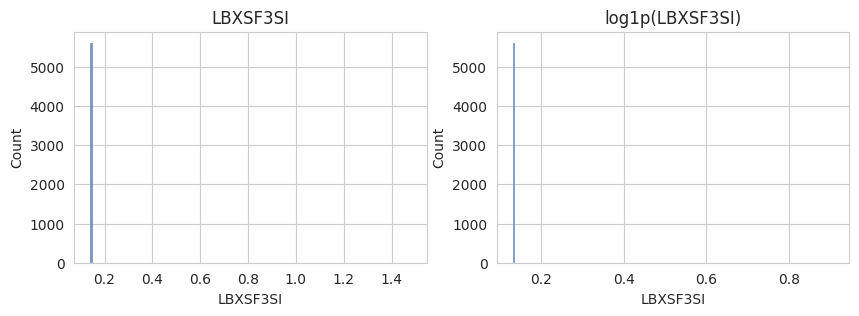

In [ ]:
askew = skew[skew > 2].index
col = askew[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sns.histplot(features[col], ax=ax[0]);                         ax[0].set_title(col)
sns.histplot(np.log1p(features[col].clip(lower=0)), ax=ax[1]); ax[1].set_title("log1p(" + col + ")")
plt.show()

In [ ]:
features_log = features.copy()
features_log[askew] = np.log1p(features_log[askew].clip(lower=0))

#PCA can’t handle NaN. For visualization only, I use the columns with <20% missing and then keep complete cases. For modelling we don’t do this, because it would throw away many samples. Mention the caveat: complete cases are a non-random subset.

Standardizing will be something to do later in the Pipeline after the train/test-split. For PCA underneath we will solely use it for visualisation

In [ ]:
# clustering

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

cont_cols = [c for c in features_log.columns if features_log[c].nunique() > 10]  # geen categorie-codes in PCA
num = features_log[cont_cols]
num = num.loc[:, num.isnull().mean() < 0.2].dropna()
print(num.shape)

X = StandardScaler().fit_transform(num)
pca = PCA(n_components=10).fit(X)
pcs = pca.transform(X)
print(pca.explained_variance_ratio_.round(3))

#Scaling comes first because PCA is variance-driven, so a variable measured in large units would dominate.
#PCA finds new axes (principal components), which are linear combinations of the original variables. PC1 is the direction of maximal variance, PC2 the next one orthogonal to PC1, and so on.
#fit learns the axes, transform gives each person’s coordinates (pcs, rows × 10).
#explained_variance_ratio_ is the fraction of total variance per PC. A low PC1+PC2 sum means a 2D plot shows only part of the structure.

(3600, 125)
[0.08  0.063 0.062 0.041 0.037 0.034 0.031 0.028 0.026 0.025]


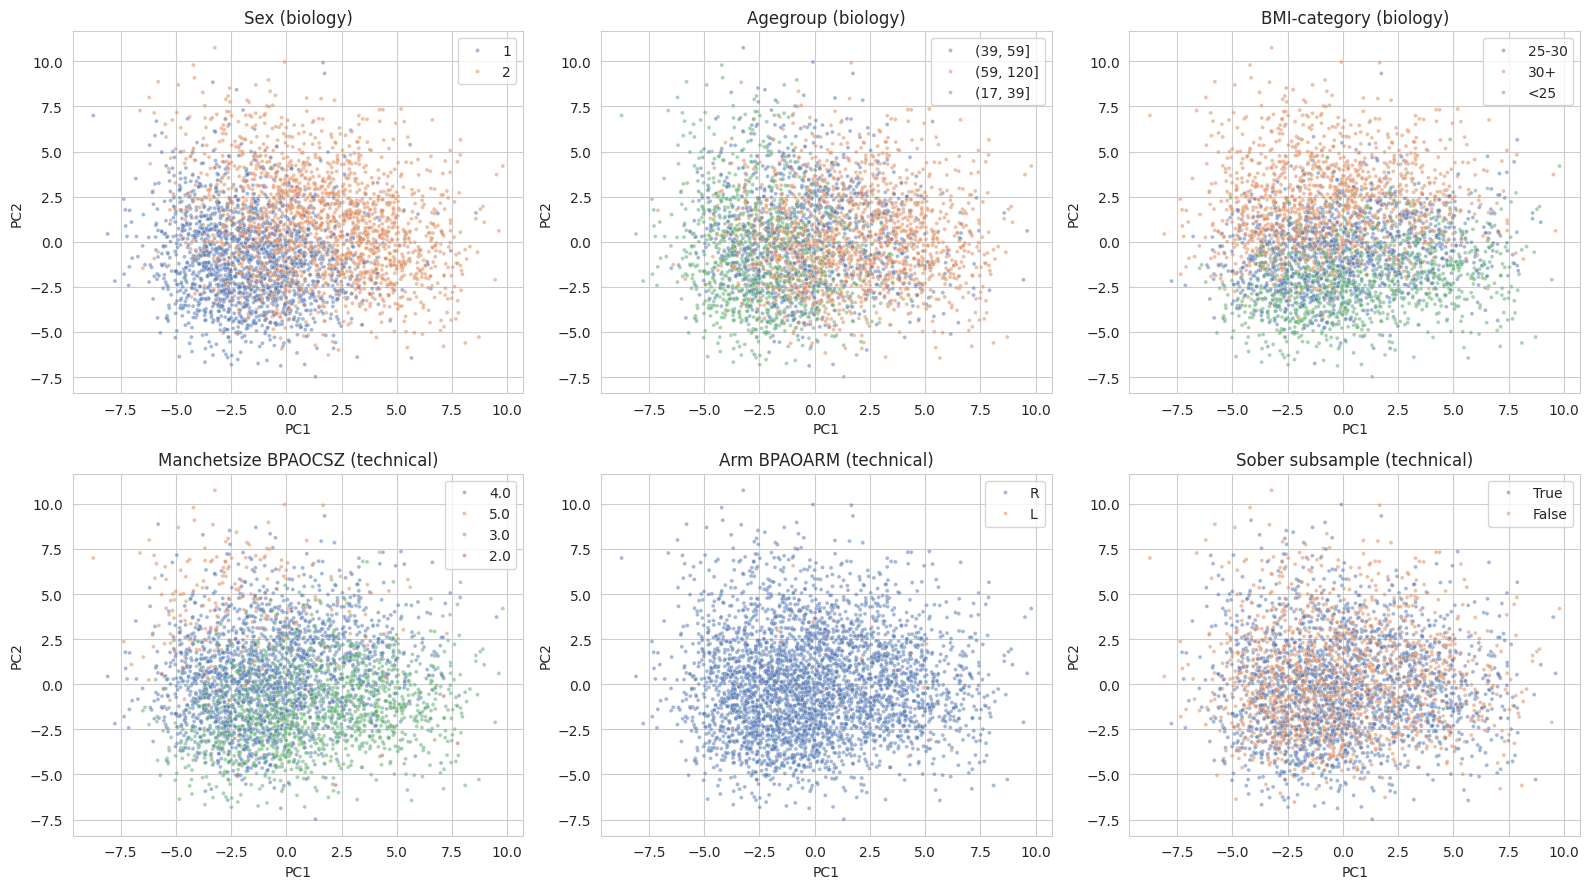

In [ ]:
meta = adults.loc[num.index]
labels = {
    "Sex (biology)": meta["RIAGENDR"].astype(str),
    "Agegroup (biology)": pd.cut(meta["RIDAGEYR"], [17, 39, 59, 120]).astype(str),
    "BMI-category (biology)": pd.cut(meta["BMXBMI"], [0, 25, 30, 100], labels=["<25", "25-30", "30+"]).astype(str),
    "Manchetsize BPAOCSZ (technical)": meta["BPAOCSZ"].astype(str),
    "Arm BPAOARM (technical)": meta["BPAOARM"].astype(str),
    "Sober subsample (technical)": meta["WTSAF2YR"].notnull().astype(str),
}

#Each entry is a way to color the plot. Biological labels: sex, age group, BMI category (cutoffs 25/30, as in Flegal 2010). Technical labels: cuff size, arm used, membership of the fasting subsample. .astype(str) makes seaborn treat them as categories.

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, lab) in zip(axes.ravel(), labels.items()):
    sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=lab.values, s=8, alpha=0.5, ax=ax)
    ax.set_title(name); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

#With scatterplot we can compare the silhouettes visually
#For each point, the mean distance to the points iwth the same label (a) with the mean distance to the nearest other label (b): (b-a)/max(a,b). It ranges from -1 to 1
#We use the first 5 PCs. A random subsample of 3000 (RandomState(0).choice, fixed seed, replace=False) is used because the silhouette is O(n²) and slow on all points. The if len(set(l)) > 1 guard skips constant labels, where the silhouette is undefined. For example, if complete cases only include the fasting subsample, that label has one value.

Scatterplot:

- near 1 means the labels separate well,
- near 0 means they overlap, with no structure for that label,
- negative means points sit closer to another group.

Expected conclusion:

biological factors (age, BMI, sex) show some structure, and technical factors are near 0. If a technical factor did separate samples, that would be a batch effect or a confound, and you’d have to correct for it or include it in the model.

In [ ]:
sub = np.random.RandomState(0).choice(len(pcs), size=min(3000, len(pcs)), replace=False)
for name, lab in labels.items():
    l = lab.values[sub]
    if len(set(l)) > 1:
        print(f"{name:40s} silhouette = {silhouette_score(pcs[sub][:, :5], l):.3f}")

Sex (biology)                            silhouette = 0.168
Agegroup (biology)                       silhouette = 0.045
BMI-category (biology)                   silhouette = 0.031
Manchetsize BPAOCSZ (technical)          silhouette = 0.016
Arm BPAOARM (technical)                  silhouette = -0.067
Sober subsample (technical)              silhouette = 0.003


In [ ]:
loadings = pd.Series(pca.components_[0], index=num.columns).sort_values(key=abs, ascending=False)
loadings.head(10)

#components_[0] are the weights of each original variable in PC1. Sorting by absolute value shows which variables drive it (probably body size: weight, waist, BMI).

,0
LBXFSH,0.215931
LBXAMH,-0.205582
LBXLUH,0.188667
LBXVIDMS,0.183798
LBXSF1SI,0.182947
RIDAGEYR,0.182882
LBDFOTSI,0.178018
LBXVD3MS,0.177181
LBXEST,-0.174833
LBXTST,-0.168734


Question 6: is the dataset suitable

Samples: 6084 | features: 160
Samples with all features: 1773
count    6084.000000
mean      122.508218
std        18.004087
min        70.000000
25%       110.333333
50%       120.000000
75%       132.000000
max       232.333333
Name: systolic_bp, dtype: float64


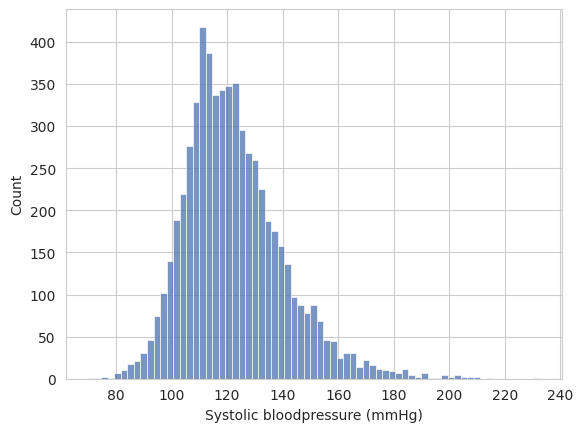

In [ ]:
y = adults.loc[features_log.index, "systolic_bp"]
print("Samples:", features_log.shape[0], "| features:", features_log.shape[1])
print("Samples with all features:", features_log.dropna().shape[0])
print(y.describe())
sns.histplot(y); plt.xlabel("Systolic bloodpressure (mmHg)"); plt.show()

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge

X_all = features_log.select_dtypes("number")
Xtr, Xte, ytr, yte = train_test_split(X_all, y, test_size=0.2, random_state=42)

#We split before fitting anything, with 20% held out as a test set that stays untouched. Lesson from the tutorial: every decision made with a dataset influences the model, so the test set must stay unseen until the end.

pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10))
scores = cross_val_score(pipe, Xtr, ytr, cv=5, scoring="r2")
print(f"Baseline cross-validated R²: {scores.mean():.2f} (± {scores.std():.2f})")

#A Pipeline chains steps, and in cross-validation it refits them on the training folds only. That is how imputation and scaling avoid leaking validation data.
#The median imputer fills NaN with the column median (robust to skew).
#Ridge is linear regression with L2 regularization. alpha sets the penalty on large coefficients (a larger alpha means a simpler model).
#cv=5 is 5-fold cross-validation: the training data is split into 5 parts, you train on 4 and validate on 1, rotating so every sample is validated once. The mean is more reliable than one split, and the std shows how much the score depends on the split.
#R² is the fraction of variance in the target explained by the model (1 = perfect, 0 = as good as predicting the mean).

Baseline cross-validated R²: 0.24 (± 0.00)


Why a baseline?

it gives a quick estimate of whether the data contain signal, and a reference that any later complex model must beat. In the tutorial the baseline was R² ≈ 0.26–0.29. A value in that range means: there is signal, but blood pressure depends on many things not in the table, so don’t expect a precise predictor.

Conclusion:

the data are suitable for regression on systolic blood pressure (many more samples than features, a clean continuous target, detectable signal). Limitations are structural missingness, non-representativeness without survey weights, leakage risk, correlated features, and modest predictive power.

**Part 2 : Formulate and test your own research question**

Research question : ....

Hypothesis : ....